# AI512: Artificial Intelligence
# Lab 3 — SOLUTION NOTEBOOK
### Informed Search, Adversarial Search, and Optimization
### Heuristics, A*, IDA*, Beam Search, Minimax, Alpha–Beta, Simulated Annealing, and Genetic Algorithms




## Setup

Run the cell below first. The lab uses only standard Python libraries plus `numpy` and `matplotlib`.


In [2]:
from __future__ import annotations
import math
import random
import heapq
from collections import deque
from typing import Dict, List, Tuple, Optional, Any
import numpy as np
import matplotlib.pyplot as plt

random.seed(2026)
np.random.seed(2026)


## Part 1 — Informed Search and Heuristics

An **informed search algorithm** uses problem-specific knowledge, usually through a heuristic function `h(n)`, to decide which state looks most promising.

For a node `n`:
- `g(n)` = cost from the start state to `n`;
- `h(n)` = estimated cost from `n` to a goal;
- `f(n) = g(n) + h(n)` for A*.

Two important heuristic properties are:
- **Admissible:** `h(n)` never overestimates the true cheapest remaining cost `h*(n)`.
- **Consistent:** for every edge `n -> n'` with cost `c`, `h(n) <= c + h(n')`.

A consistent heuristic is also admissible when `h(goal)=0`.


### Question 1.1 — Diagnose the heuristics

Consider the weighted graph below. Edge costs are shown in the code cell. For each heuristic set, determine whether it is **admissible**, **consistent**, both, or neither. Do not answer from intuition—show at least one inequality that supports your conclusion.

The first heuristic set is intentionally well-behaved; the second contains at least one subtle problem.


In [1]:
import math
import heapq


GRAPH = {
    'S': {'A': 2, 'B': 4, 'C': 3},
    'A': {'D': 4, 'E': 7},
    'B': {'E': 1, 'F': 5},
    'C': {'F': 2},
    'D': {'G': 5},
    'E': {'G': 3},
    'F': {'G': 2},
    'G': {}
}


H1 = {
    'S': 7,
    'A': 7,
    'B': 4,
    'C': 4,
    'D': 5,
    'E': 3,
    'F': 2,
    'G': 0
}


H2 = {
    'S': 7,
    'A': 9,
    'B': 4,
    'C': 5,
    'D': 5,
    'E': 3,
    'F': 2,
    'G': 0
}


def compute_true_costs(graph, goal):
    """
    Compute h*(n), the true minimum cost from every node to the goal.
    """

    # Construct the reverse graph.
    reverse_graph = {node: {} for node in graph}

    for u in graph:
        for v, cost in graph[u].items():
            reverse_graph[v][u] = cost

    # Run Dijkstra from the goal on the reversed graph.
    true_cost = {node: math.inf for node in graph}
    true_cost[goal] = 0

    pq = [(0, goal)]

    while pq:

        cost, node = heapq.heappop(pq)

        if cost != true_cost[node]:
            continue

        for predecessor, edge_cost in reverse_graph[node].items():

            new_cost = cost + edge_cost

            if new_cost < true_cost[predecessor]:

                true_cost[predecessor] = new_cost

                heapq.heappush(
                    pq,
                    (new_cost, predecessor)
                )

    return true_cost


def check_admissibility(graph, heuristic, goal):

    true_costs = compute_true_costs(graph, goal)

    violations = []

    for node in graph:

        if heuristic[node] > true_costs[node]:

            violations.append(
                (
                    node,
                    heuristic[node],
                    true_costs[node]
                )
            )

    admissible = len(violations) == 0

    return admissible, violations, true_costs


def check_consistency(graph, heuristic):

    violations = []

    for node in graph:

        for neighbour, edge_cost in graph[node].items():

            left_side = heuristic[node]

            right_side = edge_cost + heuristic[neighbour]

            if left_side > right_side:

                violations.append(
                    (
                        node,
                        neighbour,
                        left_side,
                        edge_cost,
                        heuristic[neighbour],
                        right_side
                    )
                )

    consistent = len(violations) == 0

    return consistent, violations


def classify_heuristic(graph, heuristic, goal):

    admissible, _, _ = check_admissibility(
        graph,
        heuristic,
        goal
    )

    consistent, _ = check_consistency(
        graph,
        heuristic
    )

    if admissible and consistent:
        return "Admissible and Consistent"

    elif admissible and not consistent:
        return "Admissible but Inconsistent"

    elif not admissible and consistent:
        return "Not Admissible but Consistent"

    else:
        return "Neither Admissible nor Consistent"


for name, heuristic in [('H1', H1), ('H2', H2)]:

    print("\n" + "=" * 60)
    print("Checking", name)
    print("=" * 60)

    admissible, adm_violations, true_costs = \
        check_admissibility(
            GRAPH,
            heuristic,
            'G'
        )

    consistent, con_violations = \
        check_consistency(
            GRAPH,
            heuristic
        )

    print("\nTrue remaining costs h*(n):")

    for node in sorted(true_costs):
        print(
            f"{node}: {true_costs[node]}"
        )

    print("\nAdmissible:", admissible)

    if adm_violations:

        print("\nAdmissibility violations:")

        for node, h_value, true_value in adm_violations:

            print(
                f"{node}: "
                f"h({node}) = {h_value} > "
                f"h*({node}) = {true_value}"
            )

    else:

        print("No admissibility violations.")


    print("\nConsistent:", consistent)

    if con_violations:

        print("\nConsistency violations:")

        for (
            u,
            v,
            hu,
            edge,
            hv,
            rhs
        ) in con_violations:

            print(
                f"{u} -> {v}: "
                f"h({u}) = {hu} > "
                f"{edge} + h({v}) = {rhs}"
            )

    else:

        print("No consistency violations.")


    print(
        "\nFinal classification:",
        classify_heuristic(
            GRAPH,
            heuristic,
            'G'
        )
    )



Checking H1

True remaining costs h*(n):
A: 9
B: 4
C: 4
D: 5
E: 3
F: 2
G: 0
S: 7

Admissible: True
No admissibility violations.

Consistent: True
No consistency violations.

Final classification: Admissible and Consistent

Checking H2

True remaining costs h*(n):
A: 9
B: 4
C: 4
D: 5
E: 3
F: 2
G: 0
S: 7

Admissible: False

Admissibility violations:
C: h(C) = 5 > h*(C) = 4

Consistent: False

Consistency violations:
C -> F: h(C) = 5 > 2 + h(F) = 4

Final classification: Neither Admissible nor Consistent


## Part 2 — Greedy Best-First Search

**Greedy Best-First Search (GBFS)** expands the node with the smallest `h(n)`. It ignores the path cost already paid.

### Your task
Implement `greedy_best_first_search()` so that it returns:
1. the path;
2. total path cost;
3. the expansion order.

Use **alphabetical node order to break ties** in heuristic value.


In [ ]:
def path_cost(graph, path):
    if not path:
        return -1
    return sum(graph[u][v] for u, v in zip(path, path[1:]))


def greedy_best_first_search(graph, h, start, goal):
    """Return (path, cost, expansion_order)."""
    frontier = [(h[start], start, [start])]
    visited = set()
    expansion_order = []

    while frontier:
        _, node, path = heapq.heappop(frontier)

        if node in visited:
            continue

        visited.add(node)
        expansion_order.append(node)

        if node == goal:
            return path, path_cost(graph, path), expansion_order

        for nbr in sorted(graph[node]):
            if nbr not in visited:
                heapq.heappush(frontier, (h[nbr], nbr, path + [nbr]))

    return None, -1, expansion_order


gbfs_path, gbfs_cost, gbfs_expanded = greedy_best_first_search(GRAPH, H1, 'S', 'G')
print('GBFS path       :', gbfs_path)
print('GBFS path cost  :', gbfs_cost)
print('Expansion order :', gbfs_expanded)


GBFS path       : ['S', 'B', 'F', 'G']
GBFS path cost  : 11
Expansion order : ['S', 'B', 'F', 'G']


## Part 3 — A* Search

A* combines cost-so-far and estimated remaining cost:

`f(n) = g(n) + h(n)`

### Your task
Implement graph-search A*. Your implementation must:
- use a priority queue;
- store the best `g` value found so far for each node;
- update a node when a cheaper route is discovered;
- test for the goal when it is **popped for expansion**, not merely when first generated;
- use alphabetical node order as a deterministic tie-break.


In [ ]:
def a_star_search(graph, h, start, goal):
    """Return (path, cost, expansion_order)."""
    frontier = [(h[start], start, 0, [start])]
    best_g = {start: 0}
    expansion_order = []

    while frontier:
        f, node, g, path = heapq.heappop(frontier)

        if g != best_g.get(node, math.inf):
            continue

        expansion_order.append(node)

        if node == goal:
            return path, g, expansion_order

        for nbr in sorted(graph[node]):
            new_g = g + graph[node][nbr]

            if new_g < best_g.get(nbr, math.inf):
                best_g[nbr] = new_g
                new_f = new_g + h[nbr]
                heapq.heappush(frontier, (new_f, nbr, new_g, path + [nbr]))

    return None, -1, expansion_order


astar_path, astar_cost, astar_expanded = a_star_search(GRAPH, H1, 'S', 'G')
print('A* path         :', astar_path)
print('A* path cost    :', astar_cost)
print('Expansion order :', astar_expanded)


A* path         : ['S', 'C', 'F', 'G']
A* path cost    : 7
Expansion order : ['S', 'C', 'F', 'G']


## Part 4 — IDA* (Iterative Deepening A*)

IDA* combines the low memory use of depth-first search with the heuristic guidance of A*. Instead of limiting **depth**, it repeatedly limits `f(n)=g(n)+h(n)`.

Start with `threshold = h(start)`. During a depth-first iteration:
- prune a node if `f(n) > threshold`;
- remember the smallest exceeded `f` value;
- if the goal is not found, use that minimum exceeded value as the next threshold.

For this task, use `H_IDA`, which is deliberately less informed than `H1` so that multiple threshold iterations are visible.


In [ ]:
H_IDA = {'S': 4, 'A': 5, 'B': 3, 'C': 2, 'D': 4, 'E': 2, 'F': 1, 'G': 0}


def ida_star(graph, h, start, goal):
    """Return (path, cost, thresholds, total_expansions)."""
    threshold = h[start]
    thresholds = []
    total_expansions = 0

    def dfs(path, g, bound):
        nonlocal total_expansions

        node = path[-1]
        f = g + h[node]

        if f > bound:
            return None, f

        total_expansions += 1

        if node == goal:
            return path.copy(), f

        minimum_exceeded = math.inf

        for nbr in sorted(graph[node]):
            if nbr in path:
                continue

            result, exceeded = dfs(
                path + [nbr],
                g + graph[node][nbr],
                bound,
            )

            if result is not None:
                return result, exceeded

            minimum_exceeded = min(minimum_exceeded, exceeded)

        return None, minimum_exceeded

    while True:
        thresholds.append(threshold)
        result, next_threshold = dfs([start], 0, threshold)

        if result is not None:
            return result, path_cost(graph, result), thresholds, total_expansions

        if next_threshold == math.inf:
            return None, -1, thresholds, total_expansions

        threshold = next_threshold


ida_path, ida_cost, ida_thresholds, ida_expansions = ida_star(GRAPH, H_IDA, 'S', 'G')
print('IDA* path       :', ida_path)
print('IDA* cost       :', ida_cost)
print('Thresholds      :', ida_thresholds)
print('Total expansions:', ida_expansions)


IDA* path       : ['S', 'C', 'F', 'G']
IDA* cost       : 7
Thresholds      : [4, 5, 6, 7]
Total expansions: 13


## Part 5 — Beam Search

Beam Search is a memory-bounded heuristic search. At each depth, it keeps only the best `k` candidates according to the heuristic and discards the rest.

This makes Beam Search attractive when memory is tight, but it is generally **not complete** and **not optimal**.

### Your task
Implement a level-by-level beam search. At each level:
1. generate all successors of the current beam;
2. sort candidates by `(h(node), node)`;
3. retain only the best `beam_width` candidates.

Return `(path, cost, levels)` where `levels` records the nodes kept after every beam update.


In [ ]:
def beam_search(graph, h, start, goal, beam_width=2):
    """Return (path, cost, kept_levels)."""
    if beam_width <= 0:
        raise ValueError('beam_width must be positive')

    if start == goal:
        return [start], 0, []

    beam = [(start, [start], 0)]
    kept_levels = []

    while beam:
        best_candidate = {}

        for node, path, g in beam:
            for nbr in sorted(graph[node]):
                if nbr in path:
                    continue

                ng = g + graph[node][nbr]
                candidate = (nbr, path + [nbr], ng)

                if nbr not in best_candidate or ng < best_candidate[nbr][2]:
                    best_candidate[nbr] = candidate

        if not best_candidate:
            return None, -1, kept_levels

        candidates = sorted(
            best_candidate.values(),
            key=lambda item: (h[item[0]], item[0]),
        )

        beam = candidates[:beam_width]
        kept_levels.append([node for node, _, _ in beam])

        for node, path, g in beam:
            if node == goal:
                return path, g, kept_levels

    return None, -1, kept_levels


for width in [1, 2, 3]:
    p, c, levels = beam_search(GRAPH, H1, 'S', 'G', beam_width=width)
    print(f'width={width}: path={p}, cost={c}, levels={levels}')


width=1: path=['S', 'B', 'F', 'G'], cost=11, levels=[['B'], ['F'], ['G']]
width=2: path=['S', 'C', 'F', 'G'], cost=7, levels=[['B', 'C'], ['F', 'E'], ['G']]
width=3: path=['S', 'C', 'F', 'G'], cost=7, levels=[['B', 'C', 'A'], ['F', 'E', 'D'], ['G']]


## Part 6 — Search Algorithm Comparison

After implementing Parts 2–5, fill the table programmatically. Use the same `GRAPH` and heuristic where applicable.

For `memory_comment`, use a short phrase such as `stores large frontier`, `linear in depth`, or `bounded by k per level`.


In [ ]:
def build_search_comparison(graph, h_gbfs_astar, h_ida, start='S', goal='G', beam_width=2):
    """Run Parts 2-5 and return the requested comparison dictionary."""
    gbfs_path, gbfs_cost, gbfs_expanded = greedy_best_first_search(
        graph, h_gbfs_astar, start, goal
    )
    astar_path, astar_cost, astar_expanded = a_star_search(
        graph, h_gbfs_astar, start, goal
    )
    ida_path, ida_cost, ida_thresholds, ida_expansions = ida_star(
        graph, h_ida, start, goal
    )
    beam_path, beam_cost, beam_levels = beam_search(
        graph, h_gbfs_astar, start, goal, beam_width=beam_width
    )

    beam_expansions = 1 + sum(len(level) for level in beam_levels[:-1])

    return {
        'Greedy Best-First': {
            'cost': gbfs_cost,
            'expansions': len(gbfs_expanded),
            'optimal?': 'No guarantee',
            'memory_comment': 'stores heuristic frontier',
        },
        'A*': {
            'cost': astar_cost,
            'expansions': len(astar_expanded),
            'optimal?': 'Under standard conditions',
            'memory_comment': 'stores large frontier',
        },
        'IDA*': {
            'cost': ida_cost,
            'expansions': ida_expansions,
            'optimal?': 'With admissible heuristic',
            'memory_comment': 'linear in search depth',
        },
        f'Beam Search k={beam_width}': {
            'cost': beam_cost,
            'expansions': beam_expansions,
            'optimal?': 'No guarantee',
            'memory_comment': 'bounded by k per level',
        },
    }


comparison = build_search_comparison(GRAPH, H1, H_IDA)

print(f"{'Algorithm':<22} | {'Cost':<6} | {'Expansions':<10} | {'Optimality':<27} | Memory")
print('-' * 105)

for name, d in comparison.items():
    print(
        f"{name:<22} | {str(d['cost']):<6} | {str(d['expansions']):<10} | "
        f"{d['optimal?']:<27} | {d['memory_comment']}"
    )


Algorithm              | Cost   | Expansions | Optimality                  | Memory
---------------------------------------------------------------------------------------------------------
Greedy Best-First      | 11     | 4          | No guarantee                | stores heuristic frontier
A*                     | 7      | 4          | Under standard conditions   | stores large frontier
IDA*                   | 7      | 13         | With admissible heuristic   | linear in search depth
Beam Search k=2        | 7      | 5          | No guarantee                | bounded by k per level


## Part 7 — Minimax Search

Minimax is used in deterministic, two-player, zero-sum, perfect-information games.

- **MAX** tries to maximize utility.
- **MIN** tries to minimize utility.
- Terminal nodes contain utility values.

The tree below has three plies: `MAX -> MIN -> MAX -> terminal utility`.


In [ ]:
GAME_TREE = {
    'R': ['A', 'B', 'C'],
    'A': ['A1', 'A2'],
    'B': ['B1', 'B2'],
    'C': ['C1', 'C2'],
    'A1': ['A1a', 'A1b'], 'A2': ['A2a', 'A2b'],
    'B1': ['B1a', 'B1b'], 'B2': ['B2a', 'B2b'],
    'C1': ['C1a', 'C1b'], 'C2': ['C2a', 'C2b'],
}

UTILITY = {
    'A1a': 3, 'A1b': 5,
    'A2a': 6, 'A2b': 9,
    'B1a': 1, 'B1b': 2,
    'B2a': 0, 'B2b': -1,
    'C1a': 7, 'C1b': 4,
    'C2a': 5, 'C2b': 6,
}


def minimax(node, maximizing_player=True):
    """Return the minimax value of node."""
    if node in UTILITY:
        return UTILITY[node]

    child_values = [
        minimax(child, not maximizing_player)
        for child in GAME_TREE[node]
    ]

    return max(child_values) if maximizing_player else min(child_values)


def minimax_decision(root='R'):
    """Return (best_child, value) for MAX at the root."""
    best_child = None
    best_value = -math.inf

    for child in GAME_TREE[root]:
        value = minimax(child, maximizing_player=False)

        if value > best_value:
            best_value = value
            best_child = child

    return best_child, best_value


move, value = minimax_decision('R')
print('Best root move:', move)
print('Minimax value :', value)


Best root move: C
Minimax value : 6


## Part 8 — Alpha–Beta Pruning

Alpha–Beta produces the same decision as Minimax but avoids evaluating branches that cannot influence the final choice.

- `alpha` = best value MAX can guarantee so far;
- `beta` = best value MIN can guarantee so far;
- prune when `alpha >= beta`.

### Your task
Implement Alpha–Beta and count how many terminal leaves are evaluated.


In [ ]:
def alpha_beta(node, alpha=-math.inf, beta=math.inf, maximizing_player=True, stats=None):
    """Return minimax value using Alpha-Beta pruning."""
    if stats is None:
        stats = {'leaves': 0, 'prunes': 0}

    if node in UTILITY:
        stats['leaves'] += 1
        return UTILITY[node]

    if maximizing_player:
        value = -math.inf

        for child in GAME_TREE[node]:
            value = max(
                value,
                alpha_beta(child, alpha, beta, False, stats),
            )
            alpha = max(alpha, value)

            if alpha >= beta:
                stats['prunes'] += 1
                break

        return value

    value = math.inf

    for child in GAME_TREE[node]:
        value = min(
            value,
            alpha_beta(child, alpha, beta, True, stats),
        )
        beta = min(beta, value)

        if alpha >= beta:
            stats['prunes'] += 1
            break

    return value


def alpha_beta_decision(root='R'):
    """Return (best_child, value, stats) for MAX at the root."""
    stats = {'leaves': 0, 'prunes': 0}
    best_child = None
    best_value = -math.inf
    alpha, beta = -math.inf, math.inf

    for child in GAME_TREE[root]:
        value = alpha_beta(child, alpha, beta, False, stats)

        if value > best_value:
            best_value = value
            best_child = child

        alpha = max(alpha, best_value)

    return best_child, best_value, stats


move, value, stats = alpha_beta_decision('R')
print('Best move      :', move)
print('Value          :', value)
print('Leaves examined:', stats['leaves'])
print('Prunes         :', stats['prunes'])


Best move      : C
Value          : 6
Leaves examined: 9
Prunes         : 2


## Part 9 — Simulated Annealing on the 8-Queens Problem

We now switch from path search to **optimization**.

Represent an 8-Queens state as a list of length 8. Index = column; value = row. For example:

`[0, 4, 7, 5, 2, 6, 1, 3]`

A solution has **0 attacking queen pairs**.

Simulated Annealing may sometimes accept a worse move. If `delta = new_cost - current_cost > 0`, a common acceptance probability is:

`exp(-delta / T)`

As temperature `T` decreases, accepting worse moves becomes less likely.


In [ ]:
N = 8


def queen_conflicts(state):
    """Number of attacking queen pairs. Lower is better; 0 is a solution."""
    conflicts = 0

    for c1 in range(N):
        for c2 in range(c1 + 1, N):
            same_row = state[c1] == state[c2]
            same_diag = abs(state[c1] - state[c2]) == abs(c1 - c2)

            if same_row or same_diag:
                conflicts += 1

    return conflicts


def random_neighbor(state):
    nxt = state.copy()
    col = random.randrange(N)
    old_row = nxt[col]
    choices = [r for r in range(N) if r != old_row]
    nxt[col] = random.choice(choices)
    return nxt


def temperature_schedule(t, T0=10.0, cooling=0.995):
    return T0 * (cooling ** t)


def accept_worse(delta, T):
    if delta <= 0:
        return 1.0

    if T <= 0:
        return 0.0

    return math.exp(-delta / T)


def simulated_annealing(max_steps=5000, seed=0, T0=10.0, cooling=0.995):
    random.seed(seed)

    current = [random.randrange(N) for _ in range(N)]
    current_cost = queen_conflicts(current)

    best = current.copy()
    best_cost = current_cost
    history = [best_cost]

    for t in range(max_steps):
        T = temperature_schedule(t, T0=T0, cooling=cooling)

        if T <= 1e-8 or best_cost == 0:
            break

        candidate = random_neighbor(current)
        candidate_cost = queen_conflicts(candidate)
        delta = candidate_cost - current_cost

        accepted = (
            delta <= 0
            or random.random() < accept_worse(delta, T)
        )

        if accepted:
            current = candidate
            current_cost = candidate_cost

            if current_cost < best_cost:
                best = current.copy()
                best_cost = current_cost

        history.append(best_cost)

    return best, best_cost, history


sa_state, sa_cost, sa_history = simulated_annealing(seed=7)
print('Best state     :', sa_state)
print('Best conflicts :', sa_cost)


Best state     : [2, 5, 1, 4, 7, 0, 6, 3]
Best conflicts : 0


## Part 10 — Genetic Algorithm on the 8-Queens Problem

A Genetic Algorithm maintains a **population** rather than a single current state.

For this problem:
- chromosome = list of 8 row positions;
- maximum number of non-attacking queen pairs = `C(8,2) = 28`;
- fitness can therefore be `28 - conflicts`;
- selection favors fitter chromosomes;
- crossover combines parents;
- mutation introduces variation.

### Your task
Complete tournament selection, one-point crossover, mutation, and the generation loop.


In [ ]:
MAX_PAIRS = N * (N - 1) // 2


def fitness(chromosome):
    return MAX_PAIRS - queen_conflicts(chromosome)


def random_chromosome():
    return [random.randrange(N) for _ in range(N)]


def tournament_select(population, tournament_size=3):
    k = min(tournament_size, len(population))
    competitors = random.sample(population, k)
    winner = max(competitors, key=fitness)
    return winner.copy()


def one_point_crossover(p1, p2):
    cut = random.randint(1, N - 1)
    child1 = p1[:cut] + p2[cut:]
    child2 = p2[:cut] + p1[cut:]
    return child1, child2


def mutate(chromosome, mutation_rate=0.10):
    child = chromosome.copy()

    for i in range(N):
        if random.random() < mutation_rate:
            old = child[i]
            choices = [r for r in range(N) if r != old]
            child[i] = random.choice(choices)

    return child


def genetic_algorithm(pop_size=100, generations=500, mutation_rate=0.10, seed=0):
    random.seed(seed)

    population = [
        random_chromosome()
        for _ in range(pop_size)
    ]

    best_history = []

    for gen in range(generations):
        current_best = max(population, key=fitness)
        current_best_fitness = fitness(current_best)
        best_history.append(current_best_fitness)

        if current_best_fitness == MAX_PAIRS:
            return (
                current_best.copy(),
                current_best_fitness,
                best_history,
                gen + 1,
            )

        if gen == generations - 1:
            break

        new_population = [current_best.copy()]

        while len(new_population) < pop_size:
            p1 = tournament_select(population)
            p2 = tournament_select(population)

            c1, c2 = one_point_crossover(p1, p2)
            c1 = mutate(c1, mutation_rate)
            c2 = mutate(c2, mutation_rate)

            new_population.append(c1)

            if len(new_population) < pop_size:
                new_population.append(c2)

        population = new_population

    current_best = max(population, key=fitness)

    return (
        current_best.copy(),
        fitness(current_best),
        best_history,
        len(best_history),
    )


ga_state, ga_fit, ga_history, ga_generations = genetic_algorithm(seed=7)
print('Best chromosome:', ga_state)
print('Best fitness   :', ga_fit, '/', MAX_PAIRS)
print('Conflicts      :', MAX_PAIRS - ga_fit)
print('Generations    :', ga_generations)


Best chromosome: [3, 7, 0, 2, 5, 1, 6, 4]
Best fitness   : 28 / 28
Conflicts      : 0
Generations    : 27


## Part 11 — Simulated Annealing vs Genetic Algorithm

Use repeated trials so that your conclusion does not depend on one lucky seed.

### Experimental task
Run **50 seeds** for both algorithms and collect:
- success rate;
- average final conflicts;
- median final conflicts;
- average runtime or iteration/generation count;
- best and worst final conflicts.

Then plot the distribution of final conflict counts.


Simulated Annealing:
  success rate             = 100.0%
  average conflicts        = 0.000
  median conflicts         = 0.000
  average SA iterations  = 1129.6
  best/worst conflicts     = 0 / 0
Genetic Algorithm:
  success rate             = 86.0%
  average conflicts        = 0.140
  median conflicts         = 0.000
  average GA generations = 126.4
  best/worst conflicts     = 0 / 1


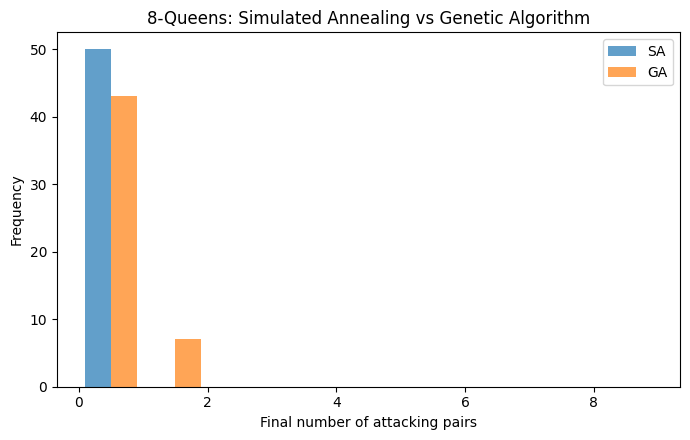

In [ ]:
def run_sa_ga_experiment(num_seeds=50):
    """Run both algorithms over the requested seeds and return separate effort measures."""
    sa_final_conflicts = []
    ga_final_conflicts = []
    sa_iterations = []
    ga_generations_used = []

    for seed in range(num_seeds):
        _, sa_cost, sa_hist = simulated_annealing(seed=seed)
        sa_final_conflicts.append(sa_cost)
        sa_iterations.append(len(sa_hist) - 1)

        _, ga_fit, ga_hist, ga_used = genetic_algorithm(seed=seed)
        ga_final_conflicts.append(MAX_PAIRS - ga_fit)
        ga_generations_used.append(ga_used)

    return (
        sa_final_conflicts,
        ga_final_conflicts,
        sa_iterations,
        ga_generations_used,
    )


def summarize_trials(name, conflicts, effort, effort_label):
    success_rate = sum(c == 0 for c in conflicts) / len(conflicts)

    print(f'{name}:')
    print(f'  success rate             = {100 * success_rate:.1f}%')
    print(f'  average conflicts        = {np.mean(conflicts):.3f}')
    print(f'  median conflicts         = {np.median(conflicts):.3f}')
    print(f'  average {effort_label:<14} = {np.mean(effort):.1f}')
    print(f'  best/worst conflicts     = {min(conflicts)} / {max(conflicts)}')


def plot_conflict_distribution(sa_final_conflicts, ga_final_conflicts):
    plt.figure(figsize=(7, 4.5))
    plt.hist(
        [sa_final_conflicts, ga_final_conflicts],
        bins=range(0, 10),
        label=['SA', 'GA'],
        alpha=0.7,
    )
    plt.xlabel('Final number of attacking pairs')
    plt.ylabel('Frequency')
    plt.title('8-Queens: Simulated Annealing vs Genetic Algorithm')
    plt.legend()
    plt.tight_layout()
    plt.show()


(
    sa_final_conflicts,
    ga_final_conflicts,
    sa_iterations,
    ga_generations_used,
) = run_sa_ga_experiment(num_seeds=50)

summarize_trials(
    'Simulated Annealing',
    sa_final_conflicts,
    sa_iterations,
    'SA iterations',
)

summarize_trials(
    'Genetic Algorithm',
    ga_final_conflicts,
    ga_generations_used,
    'GA generations',
)

plot_conflict_distribution(
    sa_final_conflicts,
    ga_final_conflicts,
)


## Part 12 — Integrated Challenge Questions

These questions are intended to test understanding rather than memorized definitions.

**Q1.** Two admissible heuristics satisfy `h2(n) >= h1(n)` for every node. Under standard A* graph-search assumptions, which heuristic is expected to expand no more nodes, and why?

**Q2.** Construct a small graph in which Greedy Best-First Search reaches a very expensive goal while A* finds a much cheaper path.

**Q3.** A Beam Search with width `k=2` fails, but width `k=3` succeeds. Does that prove width `3` is complete? Explain.

**Q4.** Why is IDA* often attractive for puzzles such as the 15-puzzle even though it re-expands states?

**Q5.** In Minimax, why can MAX not simply choose the child with the largest immediate evaluation if there are MIN moves below it?

**Q6.** Alpha–Beta prunes a branch. Does that mean the pruned branch has no legal moves, or something else? State exactly what the prune means.

**Q7.** Give an example of poor move ordering that causes Alpha–Beta to perform almost like ordinary Minimax.

**Q8.** Simulated Annealing accepts a worse state at high temperature. Explain why this is not a “bug.”

**Q9.** A Genetic Algorithm reaches identical chromosomes across the entire population but has not found a solution. Name the phenomenon and give two remedies.

**Q10.** Compare A* and Genetic Algorithms with respect to what a “state,” “successor,” and “solution” mean. Why is GA usually not described as a shortest-path algorithm?

**Q11.** For each of the following, choose the most appropriate algorithm from this lab and justify your choice: (a) shortest route with a trustworthy heuristic, (b) chess-like two-player game, (c) huge-memory-limited puzzle, (d) continuous/noisy optimization landscape, (e) population-based combinatorial optimization.

**Q12.** Suppose an A* heuristic is admissible but inconsistent. What implementation detail becomes especially important in graph search?


## Solutions — Integrated Challenge Questions

**Q1.** `h2` is said to **dominate** `h1` because `h2(n) >= h1(n)` while both remain admissible. Under the usual A* conditions, `h2` is at least as informative and is expected to expand no more nodes than `h1`, because it assigns fewer deceptively low `f=g+h` values to non-promising nodes. With inconsistent heuristics and unusual reopening/tie behavior, expansion-count details can be more subtle.

**Q2.** Example: `S→A` costs 1, `A→G` costs 100, `S→B` costs 2, `B→G` costs 2. Let `h(A)=0`, `h(B)=2`, `h(G)=0`. GBFS chooses `A` and then `G`, cost `101`. A* first explores `A`, but `G` then has `f=101`; it next explores `B` with `f=4`, updates `G` to cost `4`, and returns the cheaper route `S→B→G`.

**Q3.** No. Success on one problem with `k=3` does not make Beam Search complete. At some later depth a necessary state can still rank outside the best three candidates and be permanently discarded.

**Q4.** IDA* is attractive for puzzles because A* can exhaust memory by storing enormous frontiers. IDA* trades repeated computation for near depth-first memory usage, which is often the limiting resource in puzzles such as the 15-puzzle.

**Q5.** An immediate child value is not the final value when MIN can move afterward. MAX must assume that MIN will choose the response that minimizes MAX's eventual utility, so utilities must be backed up through the alternating MAX/MIN levels.

**Q6.** A prune does **not** mean the branch has no legal moves. It means the current `alpha` and `beta` bounds prove that no value obtainable from that branch can change the choice already available to an ancestor, so evaluating it is unnecessary.

**Q7.** A poor ordering explores weak moves first at MAX nodes and strong/high-valued moves first at MIN nodes. Bounds then tighten very late, so few cutoffs occur and Alpha–Beta can approach ordinary Minimax's work.

**Q8.** It is intentional exploration. At high temperature, occasional worse moves allow the search to leave a local optimum or cross a high-cost barrier into a better basin. The acceptance probability decreases as the algorithm cools.

**Q9.** This is **premature convergence** / loss of diversity. Remedies include increasing or adapting mutation, reducing selection pressure, injecting random immigrants/new chromosomes, or using diversity-preserving selection/replacement.

**Q10.** In A*, a state is a graph/configuration node, a successor is a legal transition, and a solution is a path to a goal whose accumulated cost can be minimized. In a GA, a chromosome is usually a complete candidate solution; new candidates are created by population operators such as selection, crossover, and mutation rather than by traversing path edges. Therefore GA normally optimizes candidate fitness, not an additive shortest-path cost.

**Q11.** (a) **A*** for a shortest route with a trustworthy heuristic; (b) **Minimax with Alpha–Beta** for a chess-like adversarial game; (c) **IDA*** for a huge puzzle when memory is tight; (d) **Simulated Annealing** for a noisy/continuous landscape where local optima are a concern; (e) **Genetic Algorithm** for population-based combinatorial optimization.

**Q12.** The implementation must allow a state to be **reopened/re-expanded when a cheaper `g` value is discovered**. With an inconsistent heuristic, permanently treating the first expansion of a state as final can lose the optimal path.
